# PREDICCIÓN COSTE ESPERADO DEL SEGURO

Con el objetivo de estimar, mediante un modelo predictivo, el coste esperado del seguro en
función de las variables que considerén oportunas, se procedera a crear diferentes tipos de modelos y se hará una comparación para determinar cual usar para dicho objetivo, nuestra variable objetivo (coste esperado) en este caso es la variable "Prima"


| Nombre                 | Definición                                                                                  |
|------------------------|---------------------------------------------------------------------------------------------|
| ID                     | Identificador único del préstamo.                                                           |
| Edad                   | Edad del prestatario.                                                                       |
| Ingresos               | Ingreso anual del prestatario.                                                              |
| Monto_Inicial          | Cantidad de dinero acordada.                                                                |
| Scoring_Crediticio     | Puntuación crediticia del prestatario que indica su solvencia.                              |
| Meses_Empleo           | Número de meses de vida laboral del prestatario.                                            |
| Num_Creditos           | Número de líneas de crédito abiertas del prestatario.                                       |
| Ratio_Interes          | Ratio de interés del préstamo (multiplicado por 100).                                       |
| Duracion               | Duración del préstamo en meses.                                                             |
| Ratio_Deuda_Ingresos   | Ratio de deuda frente a ingresos, que indica la deuda del prestatario en comparación con sus ingresos. |
| Estudios               | Nivel más alto de educación alcanzado por el prestatario.                                   |
| Tipo_Jornada_Laboral   | Tipo de jornada laboral del prestatario.                                                    |
| Estado_Civil           | Estado civil del prestatario.                                                               |
| Posesion_Hipoteca      | Indicador de si el prestatario posee una hipoteca.                                          |
| Personas_Cargo         | Número de personas a cargo del prestatario.                                                 |
| Proposito              | Propósito para el cual se solicita el préstamo.                                             |
| Fiador                 | Indicador de si el prestatario dispone de cofirmante o fiador.                              |
| Impago                 | Variable objetivo binaria que indica si el préstamo entró en mora (1) o no (0).            |
| Prima                  | Prima de la póliza de protección de pagos.                                                  |

# REGRESIÓN POLINÓMICA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os


from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
FICHERO = "df_limpio.csv"
df = pd.read_csv(os.path.join(FICHERO))

df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,Escolar,Desempleado,Soltero,1.0,1.0,Vivienda,0.0,0,65.85
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,Máster,Jornada completa,Casado,1.0,1.0,Vivienda,0.0,0,260.60
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,1.0,0,221.02
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,Grado Universitario,Jornada completa,Casado,0.0,1.0,Vivienda,0.0,0,125.00
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,Escolar,Jornada completa,Soltero,0.0,1.0,Vivienda,0.0,0,800.00


## 1. Análisis exploratorio

Hacemos un análisis exploratorio para ver el tipo de datos que tenemos, si hay nulos, la media, la desviación estandar, la mediana y asi podremos saber como hacer un correcto uso de ellos para nuestro modelo predictivo

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101899 entries, 0 to 101898
Data columns (total 19 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    101899 non-null  str    
 1   Edad                  101899 non-null  int64  
 2   Ingresos              101899 non-null  float64
 3   Monto_Inicial         101899 non-null  int64  
 4   Scoring_Crediticio    101899 non-null  int64  
 5   Meses_Empleo          101899 non-null  float64
 6   Num_Creditos          101899 non-null  int64  
 7   Ratio_Interes         101899 non-null  float64
 8   Duracion              101899 non-null  float64
 9   Ratio_Deuda_Ingresos  101899 non-null  float64
 10  Estudios              101899 non-null  str    
 11  Tipo_Jornada_Laboral  101899 non-null  str    
 12  Estado_Civil          101899 non-null  str    
 13  Posesion_Hipoteca     101899 non-null  float64
 14  Personas_Cargo        101899 non-null  float64
 15  Proposito  

In [4]:
df.describe()

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Posesion_Hipoteca,Personas_Cargo,Fiador,Impago,Prima
count,101899.000000,101899.000000,101899.0000,101899.000000,101899.000000,101899.000000,101899.000000,101899.000000,101899.000000,101899.000000,101899.000000,101899.000000,101899.000000,101899.000000
mean,39.665728,41502.751784,45009.4313,692.305322,212.913925,1.998126,10.670148,37.251133,0.321384,0.351835,0.449096,0.298661,0.115114,384.712288
std,10.103243,16033.982121,46628.3117,87.517421,151.096147,0.998255,3.797937,14.155286,0.181192,0.477541,0.497402,0.457671,0.319161,267.145901
min,19.000000,16000.000000,3000.0000,398.000000,0.000000,1.000000,2.010000,12.000000,0.100000,0.000000,0.000000,0.000000,0.000000,10.000000
25%,33.000000,30468.000000,14995.0000,636.000000,69.000000,1.000000,7.960000,24.000000,0.140000,0.000000,0.000000,0.000000,0.000000,137.470000
50%,40.000000,39082.000000,40000.0000,704.000000,208.000000,2.000000,10.600000,36.000000,0.290000,0.000000,0.000000,0.000000,0.000000,336.280000
75%,46.000000,50136.000000,47398.0000,761.000000,337.000000,3.000000,13.260000,48.000000,0.550000,1.000000,1.000000,1.000000,0.000000,610.695000
max,64.000000,120000.000000,400000.0000,845.000000,628.000000,4.000000,24.440000,60.000000,0.550000,1.000000,1.000000,1.000000,1.000000,800.000000


In [5]:
print(f"Filas y columnas: {df.shape}")
print(f"\nColumnas: {df.columns.tolist()}")

Filas y columnas: (101899, 19)

Columnas: ['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Estudios', 'Tipo_Jornada_Laboral', 'Estado_Civil', 'Posesion_Hipoteca', 'Personas_Cargo', 'Proposito', 'Fiador', 'Impago', 'Prima']


Covertimos las variables categoricas a numericas

In [6]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)

estudios_encoded = encoder.fit_transform(df[["Estudios"]])

estudios_df = pd.DataFrame(
    estudios_encoded,
    columns=encoder.get_feature_names_out(["Estudios"]),
    index=df.index
)

df = pd.concat([df.drop(columns=["Estudios"]), estudios_df], axis=1)

Visualizamos las variables

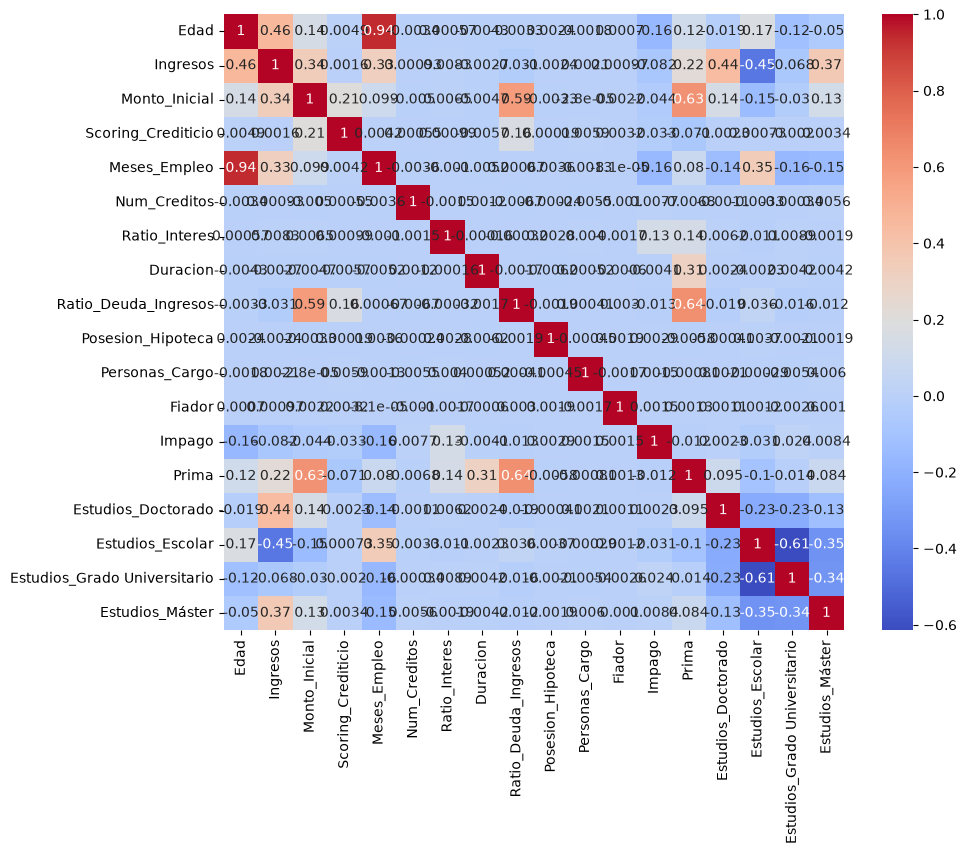

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

Ahora sepramos en train y test, separamos nuestro conjunto de df para entrenar con el 80% de los datos y usamos el 20% de test para predecir y testear nuestro modelo

In [8]:
target = "Prima"
X = df.drop(columns=[target, "ID", ""])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=X[])

SyntaxError: invalid syntax. Perhaps you forgot a comma? (4161103108.py, line 5)